# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [2]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Connect to 'enterprise_database.db'
# 2. Write a SQL query (using Window Functions or Subqueries) to get the most
#    recent status for each user.
# 3. Only keep users whose latest status is 'Active'.
# 4. Load the result into a Pandas DataFrame called 'df_active_users'.

# Connect to the SQLite database
conn = sqlite3.connect("enterprise_database.db")

# SQL query to get the most recent record for each user
# and retain only currently Active users
query = """
WITH latest_users AS (
    SELECT *,
           ROW_NUMBER() OVER (
               PARTITION BY user_id
               ORDER BY updated_at DESC
           ) AS rn
    FROM users
)
SELECT user_id, name, status, updated_at
FROM latest_users
WHERE rn = 1
AND status = 'Active';
"""

# Load SQL result into a Pandas DataFrame
df_active_users = pd.read_sql_query(query, conn)

# Display results
print(df_active_users.head())
print("Total Active Users:", len(df_active_users))

# Close database connection
conn.close()

Matplotlib is building the font cache; this may take a moment.


   user_id          name  status           updated_at
0  U-00001  User_U-00001  Active  2023-01-28 14:00:00
1  U-00003  User_U-00003  Active  2023-01-22 14:00:00
2  U-00005  User_U-00005  Active  2023-01-17 14:00:00
3  U-00006  User_U-00006  Active  2023-01-05 14:00:00
4  U-00007  User_U-00007  Active  2023-01-27 14:00:00
Total Active Users: 14183


In [3]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

# 1. Load 'server_logs.txt' into a DataFrame.
# 2. Drop any rows where the log contains the word "ERROR".
# 3. Use Pandas string methods (.str.extract()) or Python Regex to pull the
#    Date, User ID, Product ID, and Euro Value out of the raw text string.
# 4. Save this cleaned data to a new DataFrame called 'extracted_data'.

# Load the raw server logs
logs = pd.read_csv("server_logs.txt")

# Remove system error records
logs = logs[~logs["Raw_Server_Log"].str.contains("ERROR", na=False)].copy()

# Extract Date, User ID, Product ID and Euro Value using Regex
pattern = (
    r'\[(?P<Date>\d{4}-\d{2}-\d{2})'
    r'.*?"u":\s*"(?P<User_ID>U-\d+)"'
    r'.*?"item_code":\s*"(?P<Product_ID>PRD-\d+)"'
    r'.*?"eur_val":\s*(?P<Euro_Value>\d+(?:\.\d+)?)'
)

extracted_data = logs["Raw_Server_Log"].str.extract(pattern)

# Convert columns to appropriate data types
extracted_data["Date"] = pd.to_datetime(extracted_data["Date"])
extracted_data["Euro_Value"] = pd.to_numeric(
    extracted_data["Euro_Value"],
    errors="coerce"
)

# Remove any rows where extraction failed
extracted_data = extracted_data.dropna().reset_index(drop=True)

# Display results
print(extracted_data.head())
print("Total Valid Transactions:", len(extracted_data))

        Date  User_ID Product_ID  Euro_Value
0 2023-03-15  U-19484    PRD-874     3404.44
1 2023-05-09  U-18932    PRD-905     3406.21
2 2023-10-21  U-15882    PRD-284      164.08
3 2023-01-10  U-22781    PRD-665       26.80
4 2023-05-23  U-13348    PRD-589     4964.77
Total Valid Transactions: 94902


In [4]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

# 1. Load 'daily_exchange_rates.csv' into a DataFrame.
# 2. Handle the missing weekend data using a method like .fillna(method='ffill')
#    so Friday's rate rolls over to Saturday and Sunday.
# 3. Merge your cleaned logs with the exchange rates by Date.
# 4. Merge that result with your active SQL users by User ID.
# 5. Calculate a new column called 'USD_Revenue' (Euro Value * Exchange Rate).
# 6. Save the final merged table as 'df_final'.

# Load daily exchange rates
exchange_rates = pd.read_csv("daily_exchange_rates.csv")

# Convert Date to datetime
exchange_rates["Date"] = pd.to_datetime(exchange_rates["Date"])

# Convert exchange rate to numeric
exchange_rates["EUR_to_USD"] = pd.to_numeric(
    exchange_rates["EUR_to_USD"],
    errors="coerce"
)

# Forward-fill missing exchange rates
# Weekend dates receive the previous available rate
exchange_rates["EUR_to_USD"] = exchange_rates["EUR_to_USD"].ffill()

# Merge transactions with exchange rates by Date
merged_data = extracted_data.merge(
    exchange_rates,
    on="Date",
    how="left"
)

# Calculate revenue in USD
merged_data["USD_Revenue"] = (
    merged_data["Euro_Value"] * merged_data["EUR_to_USD"]
)

# Display results
print(merged_data.head())

print("Total Transactions:", len(merged_data))
print("Missing Exchange Rates:", merged_data["EUR_to_USD"].isna().sum())
print("Missing USD Revenue:", merged_data["USD_Revenue"].isna().sum())

        Date  User_ID Product_ID  Euro_Value  EUR_to_USD  USD_Revenue
0 2023-03-15  U-19484    PRD-874     3404.44    1.178232  4011.220772
1 2023-05-09  U-18932    PRD-905     3406.21    1.104983  3763.802674
2 2023-10-21  U-15882    PRD-284      164.08    1.075350   176.443420
3 2023-01-10  U-22781    PRD-665       26.80    1.127128    30.207030
4 2023-05-23  U-13348    PRD-589     4964.77    1.019626  5062.207773
Total Transactions: 94902
Missing Exchange Rates: 0
Missing USD Revenue: 0


Monthly Revenue:
      Month   USD_Revenue
0   2023-01  2.223762e+07
1   2023-02  1.991433e+07
2   2023-03  2.192945e+07
3   2023-04  2.122658e+07
4   2023-05  2.224473e+07
5   2023-06  2.143139e+07
6   2023-07  2.220097e+07
7   2023-08  2.251517e+07
8   2023-09  2.156016e+07
9   2023-10  2.184012e+07
10  2023-11  2.214062e+07
11  2023-12  2.200072e+07

Top 5 Customers:
       User_ID   USD_Revenue
19318  U-19750  44819.126098
20120  U-20570  44287.518225
5515   U-05640  43503.896034
418    U-00425  41970.696334
16958  U-17335  41550.520140


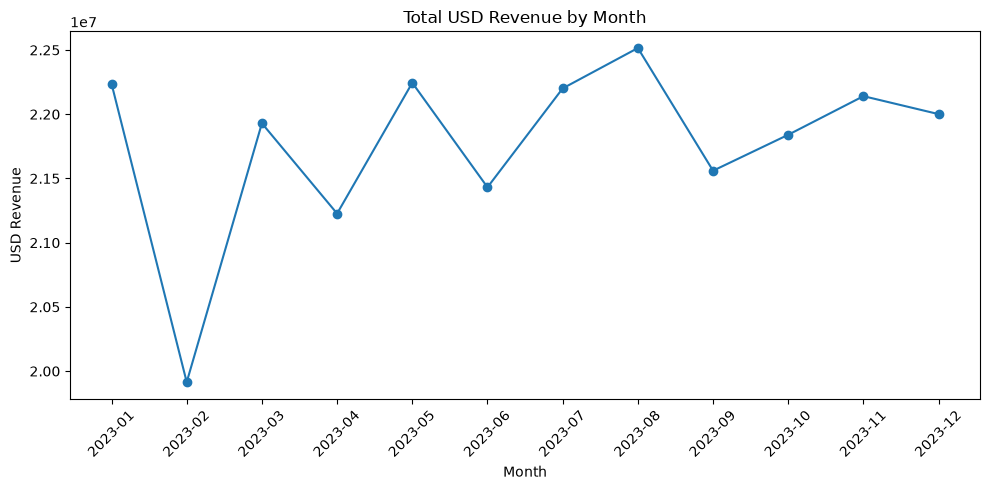

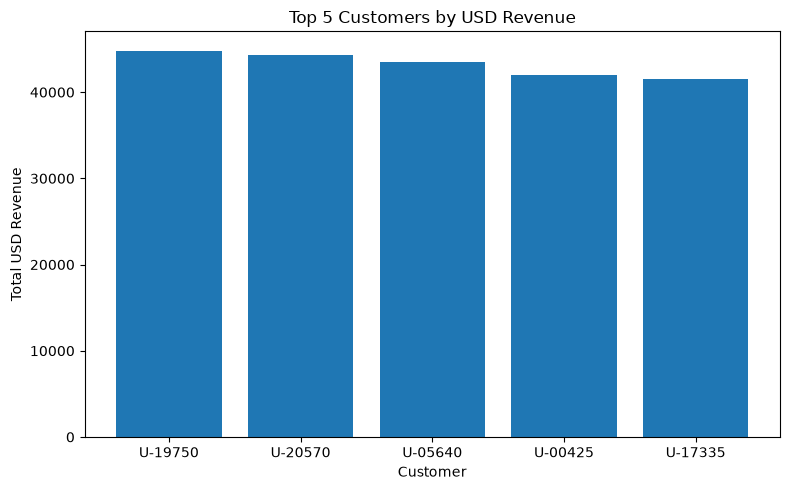

In [5]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

# 1. Group the data in 'df_final' to calculate Total USD Revenue by Month.
# 2. Group the data to find the Top 5 Most Valuable Customers by Total USD spent.
# 3. Use Matplotlib or Seaborn to generate two charts side-by-side:
#    - Chart 1: A Line Chart or Bar Chart showing Revenue by Month.
#    - Chart 2: A Bar Chart showing the Top 5 Customers.
# 4. Ensure your charts have titles, clean axes, and are easy to read.

# Create final dataset
df_final = merged_data.copy()

# Add Month column for monthly aggregation
df_final["Month"] = df_final["Date"].dt.to_period("M").astype(str)

# 1. Calculate Total USD Revenue by Month
monthly_revenue = (
    df_final.groupby("Month", as_index=False)["USD_Revenue"]
    .sum()
)

# 2. Find Top 5 Customers by Total USD Revenue
top_5_customers = (
    df_final.groupby("User_ID", as_index=False)["USD_Revenue"]
    .sum()
    .sort_values("USD_Revenue", ascending=False)
    .head(5)
)

print("Monthly Revenue:")
print(monthly_revenue)

print("\nTop 5 Customers:")
print(top_5_customers)

# Chart 1: Revenue by Month
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["USD_Revenue"],
    marker="o"
)

plt.title("Total USD Revenue by Month")
plt.xlabel("Month")
plt.ylabel("USD Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Chart 2: Top 5 Customers
plt.figure(figsize=(8, 5))
plt.bar(
    top_5_customers["User_ID"],
    top_5_customers["USD_Revenue"]
)

plt.title("Top 5 Customers by USD Revenue")
plt.xlabel("Customer")
plt.ylabel("Total USD Revenue")
plt.tight_layout()
plt.show()

In [6]:
# PHASE 5: BI HANDOFF

# Export final cleaned and merged dataset
merged_data.to_csv("power_bi_ready_dataset.csv", index=False)

print("Export successful!")
print("File: power_bi_ready_dataset.csv")
print("Rows exported:", len(merged_data))

Export successful!
File: power_bi_ready_dataset.csv
Rows exported: 94902
